# Medical prognosis from public chest X-rays

We use **948 public TCIA chest radiographs from distinct patients**, with **164 later in-hospital deaths**. A single frontal image is selected from the day before or day of the chosen inpatient admission. Stays ending on the admission day are excluded. The prediction landmark is the start of hospital day two; exact death timestamps are unavailable. Splits are by patient (663 train / 142 validation / 143 test). This is internal validation at one site.

Source: Saltz et al. (2021), [TCIA COVID-19-NY-SBU](https://www.cancerimagingarchive.net/collection/covid-19-ny-sbu/), [DOI 10.7937/TCIA.BBAG-2923](https://doi.org/10.7937/TCIA.BBAG-2923), CC BY 4.0. First preparation transfers about 14 GB of public DICOM data and retains about 200 MB of converted PNGs, without storing the raw DICOM files. Dates are shifted in the source.

Both demos use **8,192 dictionary entries**, the package's default dictionary width. The CPU example uses a coarse candidate grid and a 2,000-step training budget. The first tested k reaching validation R²≥0.85 defines k₀; R²≥0.90 allows k≤2k₀, and R²≥0.95 allows k≤3k₀. Selection uses validation reconstruction, not test outcomes. Initial encoder gain is calibrated using training inputs only.

From a Glyph checkout, install `pip install -e ".[hf]" "pydicom>=3.0" "idc-index-data==25.0.5"` and open this notebook. Approved access and a configured HF login are needed for [`facebook/dinov3-vits16-pretrain-lvd1689m`](https://huggingface.co/facebook/dinov3-vits16-pretrain-lvd1689m). Model revision is pinned. No author research data or LLM key is used.

The recorded execution below reloads a real local run when available; a fresh checkout follows the raw-input fitting branch. Embeddings were extracted with Glyph's HF adapter and the actual pretrained weights. The local saved models and full input caches are excluded from Git.


In [1]:
from pathlib import Path
import json, os, warnings
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from glyph import Glyph

repo = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "examples/sbu_cxr.py").is_file())
os.chdir(repo)
from examples.sbu_cxr import prepare, make_glyph, example_panels, literature_study
torch.set_num_threads(8)
warnings.filterwarnings("ignore", category=FutureWarning, module=r"sklearn\..*")

# Optional recorded run. Absent on a fresh checkout, which computes a new run.
saved_run = repo / 'demo_outputs/medical_8192_20261027T013257705922/runs/20261027T013258Z-97a8ed6bbd'
output = repo / 'demo_outputs/medical_8192_20261027T013257705922'
output.mkdir(parents=True, exist_ok=True)
use_saved_run = saved_run.is_dir()
print("Reloading recorded run" if use_saved_run else "Starting from public raw inputs")


/dataNAS/people/rholland/micromamba/envs/venv_torch/lib/python3.11/site-packages/lightning_fabric/__init__.py:40: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.


Reloading recorded run


## 1. Public inputs and labels

The helper selects inputs independently of outcome labels. Labels stratify the patient/image splits.


split
test     143
train    663
val      142
Later deaths: 164


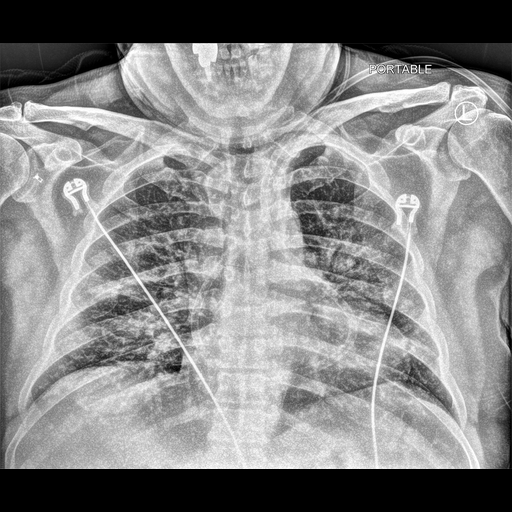

In [2]:
if use_saved_run:
    glyph = Glyph.load_run(saved_run, device="cpu")
    metadata = Path(glyph.cfg.data.metadata)
else:
    metadata_file = output / "inputs/metadata.csv"
    metadata = metadata_file if metadata_file.exists() else prepare(output / "inputs")
    glyph = make_glyph(metadata, output / "runs")

frame = pd.read_csv(metadata)
print(frame.groupby("split").size().to_string())
print("Later deaths:", int(frame.in_hospital_death.sum()))
preview = frame.loc[frame.split.eq("train"), "image_path"].iloc[0]
display(Image(filename=str(preview), width=360))


## 2. Extract embeddings and learn the full-width dictionary

On a fresh run, `fit` extracts DINOv3 embeddings and learns the dictionary. Reloading a completed run skips extraction and fitting. The table reports every tested k.


In [3]:
if not use_saved_run:
    glyph.fit()
selection = glyph.sae_models["image_path"].selection_report
assert selection["dictionary_size"] == 8192
print("Dictionary entries:", selection["dictionary_size"])
print("Selected k:", selection["selected_top_k"])
print("Validation R²:", selection["selected_validation_r2"])
print(pd.DataFrame(selection["tried"])[["top_k", "validation_r2"]].to_string(index=False))


Dictionary entries: 8192
Selected k: 768
Validation R²: 0.9045076900969415
 top_k  validation_r2
     8       0.467423
    16       0.537642
    32       0.604841
    64       0.681907
   128       0.758704
   256       0.824059
   512       0.875851
   640       0.891201
   768       0.904508
   896       0.913967
  1024       0.921277
  1152       0.927324
  1280       0.932807
  1408       0.937688
  1536       0.941304


## 3. Test associations and create the explorer

The map shows all training-active concepts, preserving their original indices in the 8,192-entry dictionary. Bonferroni correction uses the saved testing family. No automated interpretation or confounder adjustment is requested.


Node area is proportional to activation prevalence, with a tiny floor and a common density adjustment. Correlation lines are visible by default, capped at eight per concept.

Node area is proportional to activation prevalence, with a tiny floor and a common density adjustment. Correlation lines are visible by default, capped at eight per concept.

In [4]:
if glyph.phewas_results is None:
    glyph.hypothesis_search()
html_path = repo / 'demo_outputs/prevalence_sizing_sbu_cxr_20261027T214250/explorer.html'
if not html_path.exists():
    html_path = Path(glyph.visualize(split="train")[0])
print("Explorer:", html_path)
example_panels(glyph, output)


Explorer: /dataNAS/people/rholland/Glyph/demo_outputs/prevalence_sizing_sbu_cxr_20261027T214250/explorer.html


## 4. Compare against a literature baseline and generate the brief

We use a targeted lookup of [Williamson et al., Nature 2020](https://pmc.ncbi.nlm.nih.gov/articles/PMC7611074/) supporting age and sex as mortality risk factors. Available age bands are proxies. This is a simplified age/sex baseline, not their published fitted model or a systematic review. The full Glyph arm uses all training-active concepts. We also compare up to ten predictors per source and the literature baseline plus the highest-ranked Glyph concepts up to ten total predictors. The capped combination retains all three available literature predictors and adds seven Glyph concepts. The capped combination retains all three available literature predictors and adds seven Glyph concepts. The capped combination retains all three available literature predictors and adds seven Glyph concepts. The capped combination retains all three available literature predictors and adds seven Glyph concepts. Ranking uses training-only two-sided logistic score tests, validation selects both predictor checkpoints and ridge penalties, with separate literature/Glyph penalties in combined models, and every selection is frozen before test evaluation. The literature pool has three predictors, so its full and top-ten variants coincide. Test intervals and comparisons use 1,000 paired patient bootstrap resamples.

The PDF includes the entire active concept space, followed by one page per selected concept with its local map, exact statistics and actual activating training/held-out images together. Images are selected by activation, without outcome-based selection; this is not semantic interpretation validation.


Concept pages show a zero-activation image, then 33rd/66th/100th percentiles among positive training activations, followed by the high-activation tail. The HTML report has expandable tail panels. Predictor checkpoints and penalties use validation only, with patience 20 and separate literature/Glyph block penalties. Comparison brackets show exploratory paired-bootstrap p-values and stars. [Expandable HTML report](report_files/report.html).

Concept pages show a zero-activation image, then 33rd/66th/100th percentiles among positive training activations, followed by the high-activation tail. The HTML report has expandable tail panels. Predictor checkpoints and penalties use validation only, with patience 20 and separate literature/Glyph block penalties. Comparison brackets show exploratory paired-bootstrap p-values and stars. [Expandable HTML report](report_files/report.html).

{'n_concepts': 8192, 'n_significant_pairs': 46, 'n_comparable_hits': 31, 'n_reproduced_hits': 1}
split                      arm      auc  ci_lower  ci_upper
 test               Literature 0.839153  0.770665  0.906134
 test        Literature top 10 0.839153  0.770665  0.906134
 test                    Glyph 0.783390  0.660914  0.892617
 test             Glyph top 10 0.766610  0.624588  0.880259
 test Literature + Glyph to 10 0.932034  0.876807  0.974805


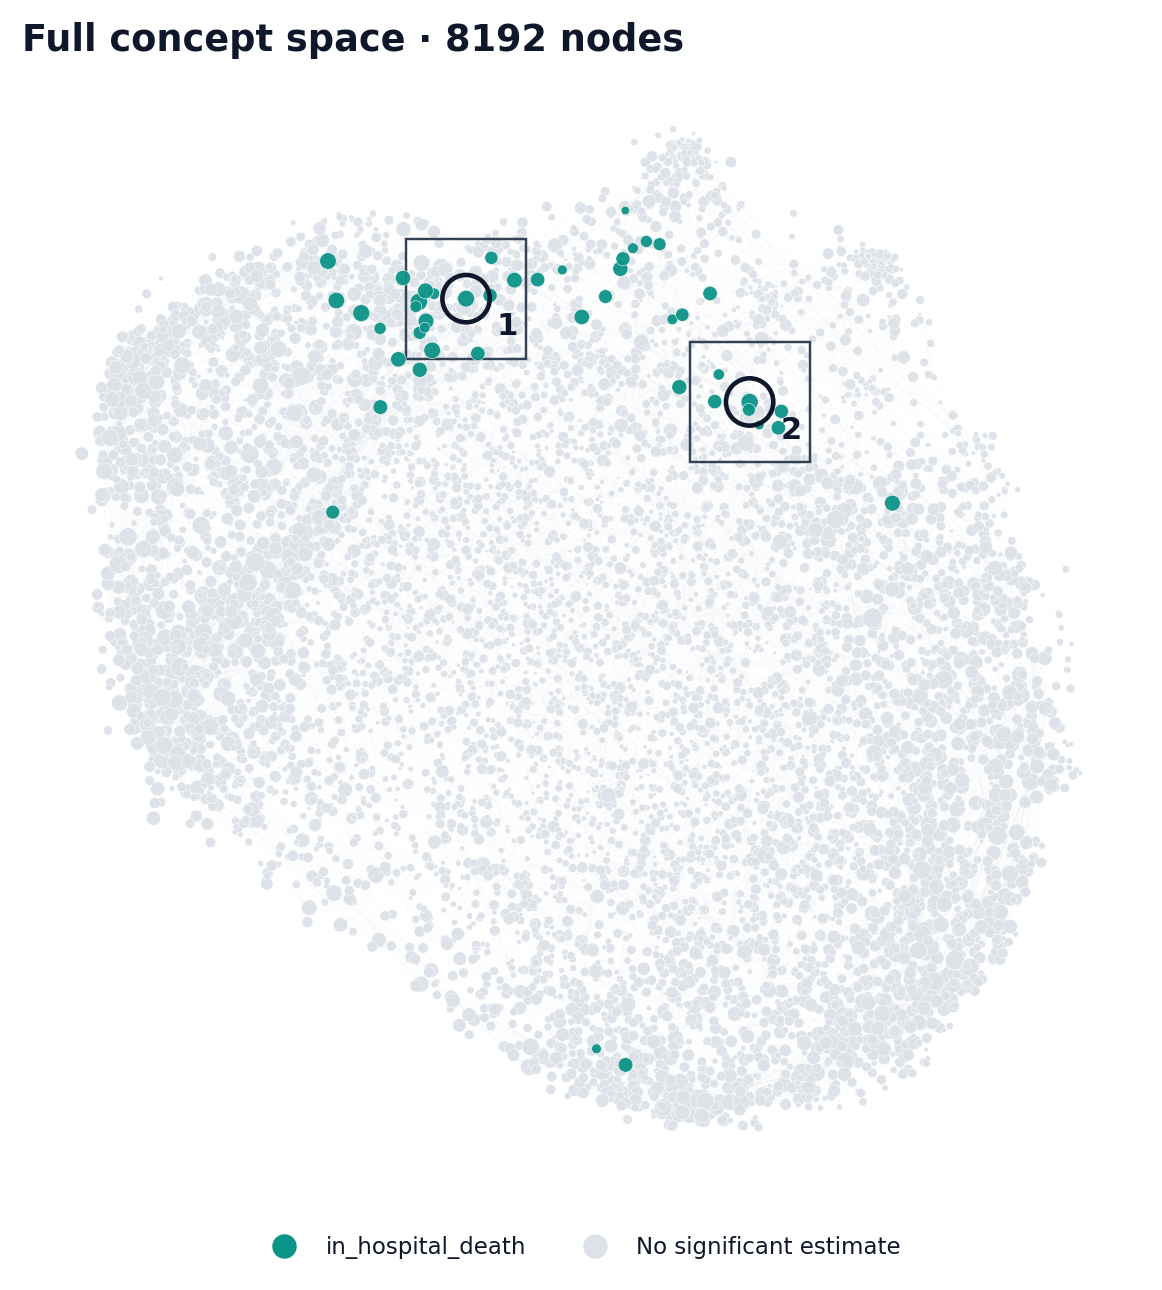

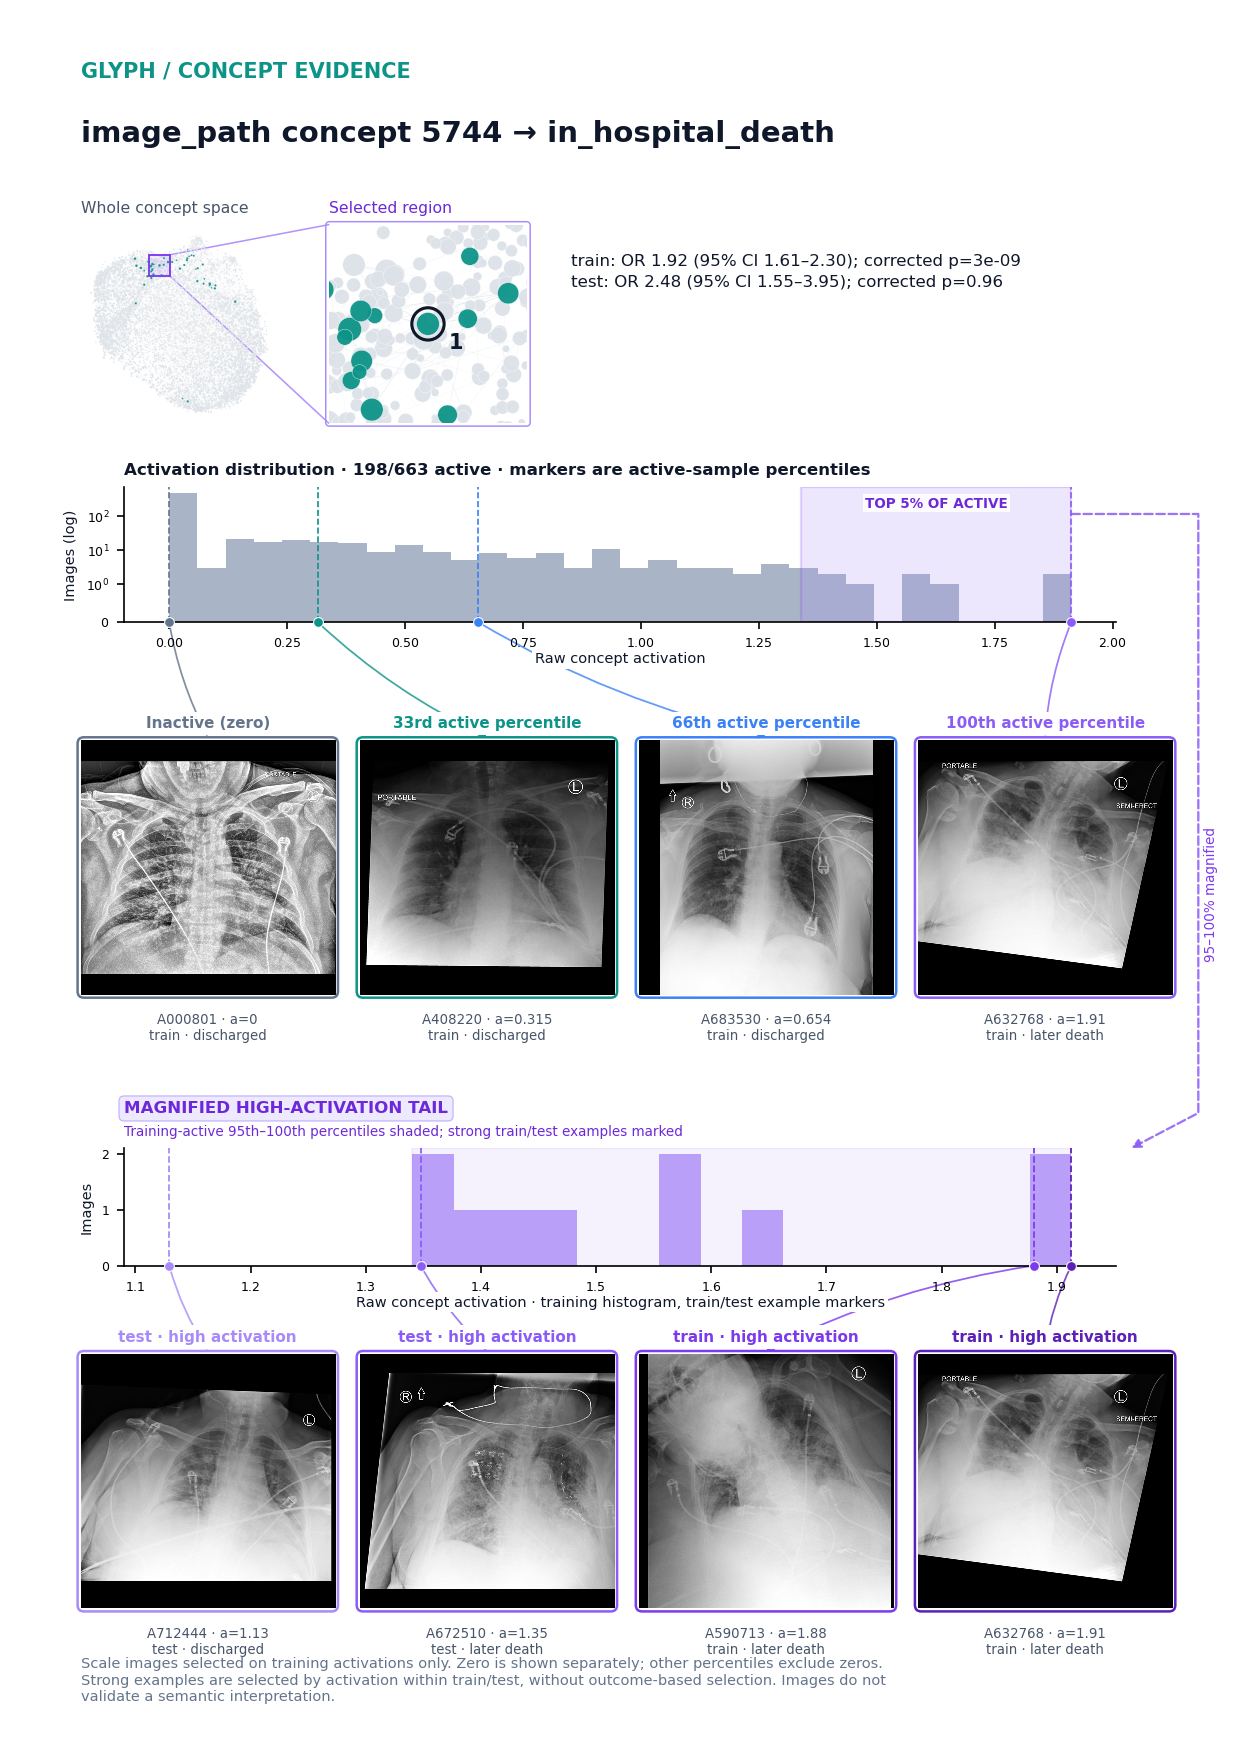

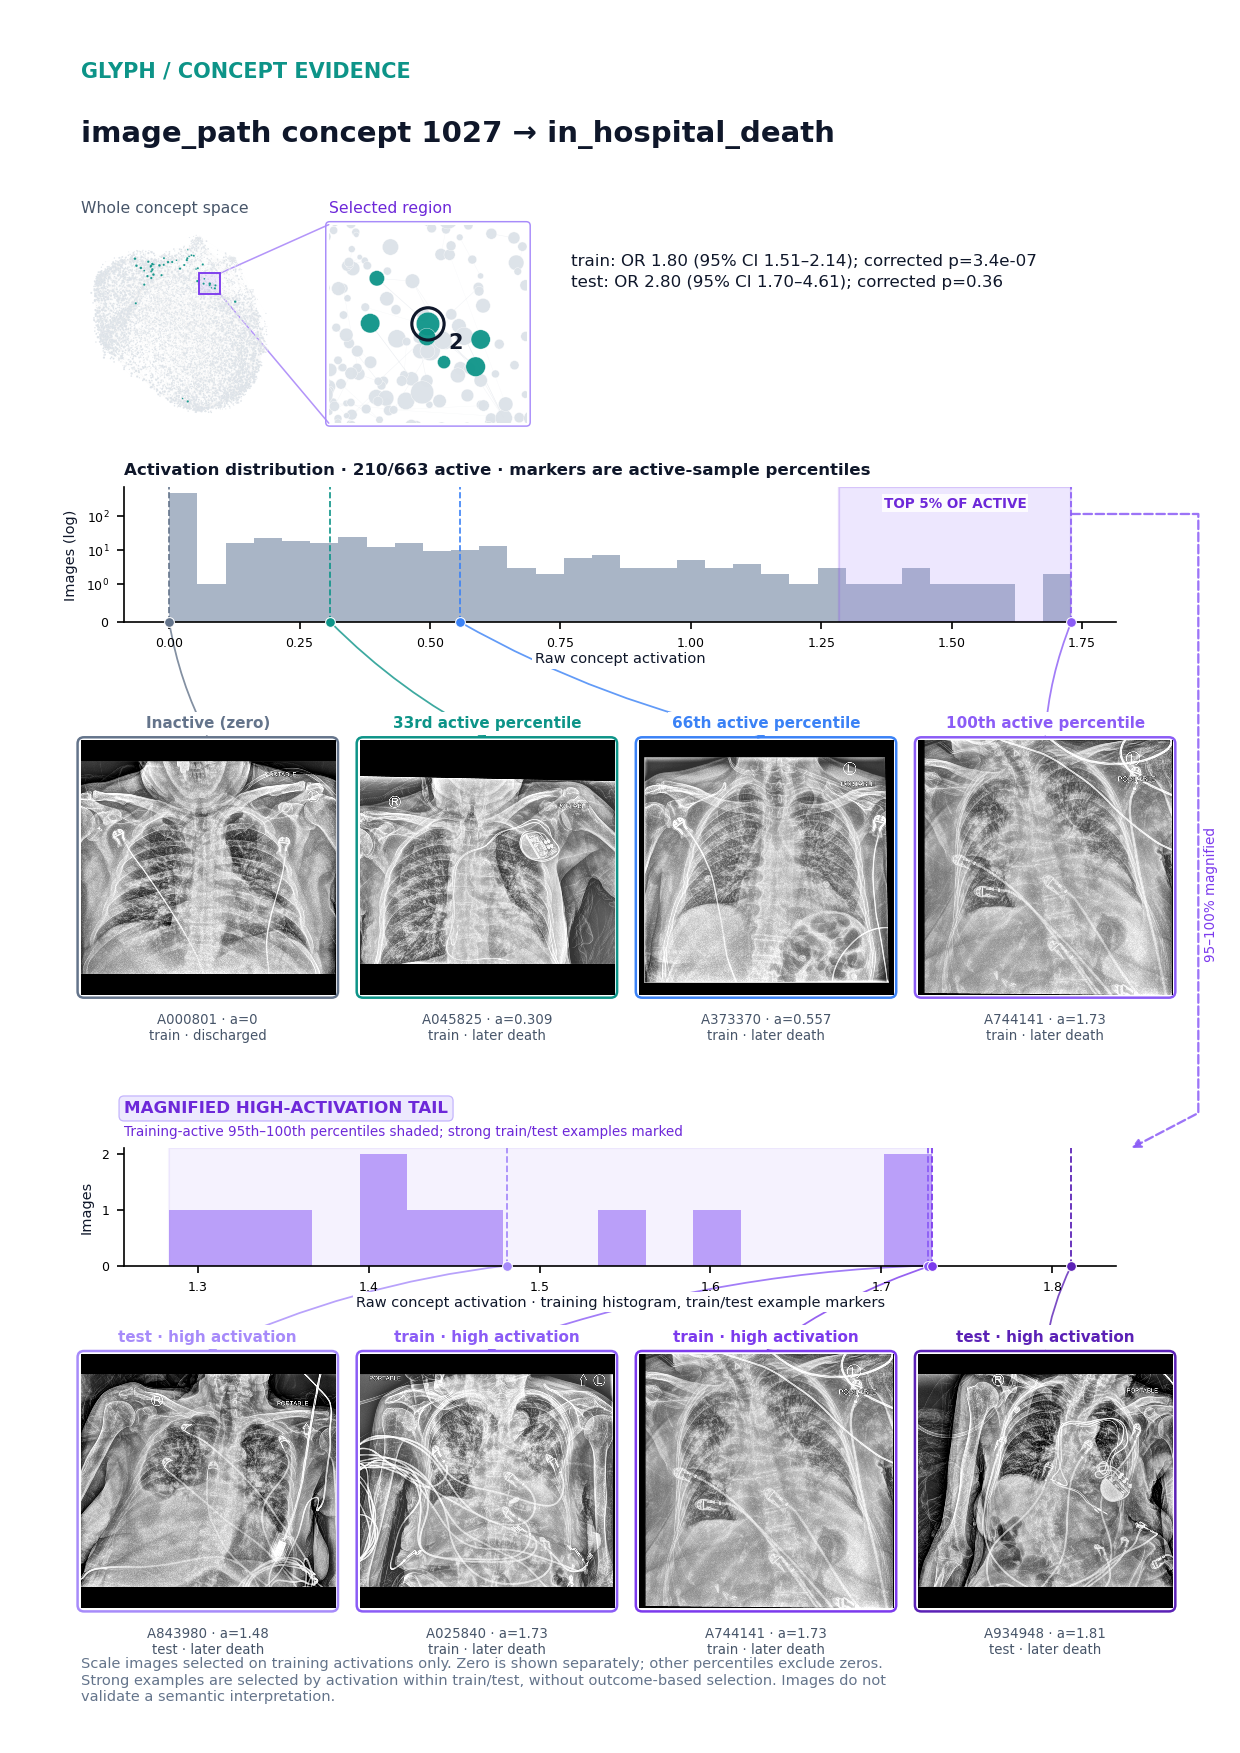

PDF: /dataNAS/people/rholland/Glyph/demo_outputs/prevalence_sizing_sbu_cxr_20261027T223802/report_files/report.pdf


In [5]:
report_dir = repo / 'demo_outputs/prevalence_sizing_sbu_cxr_20261027T223802/report_files'
if not (report_dir / "report.pdf").exists():
    comparison_output = repo / 'demo_outputs/medical_comparison6_20261027T220211'
    study = literature_study(glyph, Path(metadata).parent, comparison_output / "literature")
    report_dir = study / "report"
facts = json.loads((report_dir / "facts.json").read_text())
print({key: facts[key] for key in ["n_concepts", "n_significant_pairs", "n_comparable_hits", "n_reproduced_hits"]})
intervals = pd.read_csv(repo / 'demo_outputs/medical_comparison6_20261027T220211/literature/study/comparison/auc_intervals.csv')
print(intervals[intervals.arm.ne("Literature + Glyph")].to_string(index=False))
display(Image(filename=str(report_dir / "concept_space.png"), width=900))
for i, item in enumerate(facts["image_examples"]):
    display(Image(filename=str(report_dir / f"concept_{i+1}.png"), width=850))
print("PDF:", report_dir / "report.pdf")


## 5. Reload the saved dictionary

Reuse its stored parameters and normalization. This check uses the same CPU thread setting as the recorded run.


In [6]:
loaded = Glyph.load_run(glyph.run_dir, device="cpu")
for split, data in glyph.embeddings.items():
    extracted = loaded.encode_embeddings(data["embeddings"]["image_path"], modality="image_path")
    torch.testing.assert_close(extracted, glyph.sae_features["image_path"][split], rtol=0, atol=0)
print("Exact saved activation reload passed")


Exact saved activation reload passed


## View the curated files

[Interactive explorer](explorer.html) · [PDF report](report.pdf) · [Markdown report](report_files/report.md)

GitHub renders the notebook and PDF. Download the self-contained HTML and open it locally for interaction. The report distinguishes discovery significance, held-out association estimates and predictive model performance. No new biological discovery or external clinical validation is established by this demo.
